# Forecasting US housing markets with Zillow's public data

**Question:** using only what is known at the end of a year, how well can we predict each US metro's home value growth over the next 12 months, and where do the models break?

The notebook runs top to bottom on Zillow's public metro-level data (ZHVI home values and ZORI rents):

| Part | What it does | Tools |
|---|---|---|
| 1 | Forecast next-year home value growth for ~900 metros; time-based holdout, then a rolling-origin backtest | scikit-learn (ridge, gradient boosting) |
| 2 | Market metrics on the metro-by-month panel: YoY growth, price-to-rent, peak-to-now drawdown | SQL (DuckDB window functions, CTEs, `QUALIFY`) |
| 3 | The same pipeline at scale | PySpark DataFrames, window specs, Spark SQL |
| 4 | Segment metros by how their market behaves | k-means, silhouette, PCA |

**Data:** download two CSVs from <https://www.zillow.com/research/data/> (Metro & U.S.) into `data/` (see the README). Without them the notebook runs on synthetic data with the same layout, so every cell still works.

In [1]:
import os
from pathlib import Path

# PySpark needs Java 17+; setup.sh saves its location to .java_home
if not os.environ.get("JAVA_HOME") and Path(".java_home").exists():
    os.environ["JAVA_HOME"] = Path(".java_home").read_text().strip()

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("data")
ZHVI_FILE = DATA / "Metro_zhvi_uc_sfrcondo_tier_0.33_0.67_sm_sa_month.csv"
ZORI_FILE = DATA / "Metro_zori_uc_sfrcondomfr_sm_month.csv"
ID_COLS = ["RegionID", "SizeRank", "RegionName", "RegionType", "StateName"]

### Synthetic fallback
Only used when the real CSVs are missing. It mimics Zillow's wide layout: one row per region, one column per month-end date.

In [3]:
def make_synthetic(n_metros=150, seed=0):
    rng = np.random.default_rng(seed)
    states = ["TX", "CA", "FL", "NY", "WA", "CO", "OH", "GA", "AZ", "NC", "IL", "PA", "MI", "TN", "VA"]
    dates = pd.date_range("2000-01-31", "2026-08-31", freq="ME")
    names = ["United States"] + [f"Metro {i}, {states[i % len(states)]}" for i in range(1, n_metros)]
    base = np.exp(rng.normal(12.3, 0.45, n_metros))
    trend = rng.normal(0.0035, 0.0012, n_metros)               # monthly drift
    boom = rng.uniform(0.5, 2.0, n_metros)                     # how hard the 2020-22 run-up hit
    t = np.arange(len(dates))
    shock = np.where((dates >= "2007-06") & (dates <= "2011-12"), -0.004, 0) \
          + np.where((dates >= "2020-06") & (dates <= "2022-06"), 0.010, 0)
    noise = rng.normal(0, 0.002, (n_metros, len(dates))).cumsum(axis=1)
    log_v = np.log(base)[:, None] + trend[:, None] * t + boom[:, None] * shock.cumsum() + noise
    zhvi = pd.DataFrame(np.exp(log_v).round(), columns=dates.strftime("%Y-%m-%d"))
    for i in rng.choice(np.arange(60, n_metros), 25, replace=False):   # small metros start late
        zhvi.iloc[i, : rng.integers(12, 120)] = np.nan
    meta = pd.DataFrame({"RegionID": 100000 + np.arange(n_metros), "SizeRank": np.arange(n_metros),
                         "RegionName": names, "RegionType": ["country"] + ["msa"] * (n_metros - 1),
                         "StateName": [None] + [n.split(", ")[1] for n in names[1:]]})
    zhvi = pd.concat([meta, zhvi], axis=1)

    rent_dates = dates[dates >= "2015-01-31"].strftime("%Y-%m-%d")
    ptr = rng.uniform(12, 30, n_metros)                         # price-to-annual-rent ratio
    zori = zhvi[rent_dates].div(ptr * 12, axis=0) * np.exp(rng.normal(0, 0.01, (n_metros, len(rent_dates))))
    zori = pd.concat([meta, zori.round()], axis=1).drop(index=rng.choice(np.arange(80, n_metros), 30, replace=False))
    return zhvi, zori


if ZHVI_FILE.exists() and ZORI_FILE.exists():
    zhvi_wide, zori_wide = pd.read_csv(ZHVI_FILE), pd.read_csv(ZORI_FILE)
    SYNTHETIC = False
else:
    print("Real Zillow files not found in data/ -> using SYNTHETIC data. Numbers are not real.")
    zhvi_wide, zori_wide = make_synthetic()
    SYNTHETIC = True

zhvi_wide.iloc[:5, :8]

,RegionID,SizeRank,RegionName,RegionType,StateName,2000-01-31,2000-02-29,2000-03-31
0,102001,0,United States,country,NaN,122625.740358,122841.478347,123109.025217
1,394913,1,"New York, NY",msa,NY,217974.228192,218900.495676,219835.342067
2,753899,2,"Los Angeles, CA",msa,CA,220915.331492,221737.416820,222832.426636
3,394463,3,"Chicago, IL",msa,IL,154896.363525,155039.752434,155312.839139
4,394514,4,"Dallas, TX",msa,TX,128861.144503,128918.539707,128984.521370


### Wide to long ("tidy")
Databases and Spark want one row per (region, month). This reshape is the single most common step with Zillow's files.

In [4]:
def to_long(wide, value_name):
    return (wide.melt(id_vars=ID_COLS, var_name="date", value_name=value_name)
                .assign(date=lambda d: pd.to_datetime(d["date"]))
                .dropna(subset=[value_name]))

zhvi = to_long(zhvi_wide, "zhvi")
zori = to_long(zori_wide, "zori")
print(f"zhvi: {len(zhvi):,} rows, {zhvi.RegionID.nunique()} regions, {zhvi.date.min():%Y-%m} to {zhvi.date.max():%Y-%m}")
print(f"zori: {len(zori):,} rows, {zori.RegionID.nunique()} regions, {zori.date.min():%Y-%m} to {zori.date.max():%Y-%m}")
zhvi.head()

zhvi: 238,029 rows, 895 regions, 2000-01 to 2026-09
zori: 53,977 rows, 741 regions, 2015-01 to 2026-09


,RegionID,SizeRank,RegionName,RegionType,StateName,date,zhvi
0,102001,0,United States,country,NaN,2000-01-31,122625.740358
1,394913,1,"New York, NY",msa,NY,2000-01-31,217974.228192
2,753899,2,"Los Angeles, CA",msa,CA,2000-01-31,220915.331492
3,394463,3,"Chicago, IL",msa,IL,2000-01-31,154896.363525
4,394514,4,"Dallas, TX",msa,TX,2000-01-31,128861.144503


---
## Part 1: Forecasting next-year growth

Each row is one metro at the end of one year. Features use data up to that month only; the target is growth over the following 12 months, so there is **no leakage**. Validation is **time-based**: a random split would let the model peek at the future.

In [5]:
panel = zhvi_wide.query("RegionType == 'msa'").set_index("RegionName")
dates = pd.to_datetime(panel.columns[len(ID_COLS) - 1:])
vals = panel.iloc[:, len(ID_COLS) - 1:].set_axis(dates, axis=1).astype(float)

rows = []
for t in [d for d in dates if d.month == 12 and d.year >= 2005]:
    i = dates.get_loc(t)
    if i + 12 >= len(dates):
        break
    now, fut = vals.iloc[:, i], vals.iloc[:, i + 12]
    rows.append(pd.DataFrame({
        "year": t.year + 1,                                   # the year being predicted
        "log_value": np.log(now),
        "growth_1y": now / vals.iloc[:, i - 12] - 1,
        "growth_3y": now / vals.iloc[:, i - 36] - 1,
        "momentum_6m": now / vals.iloc[:, i - 6] - 1,
        "volatility": vals.iloc[:, i - 24:i + 1].pct_change(axis=1).std(axis=1),
        "target": fut / now - 1,
    }))
data = pd.concat(rows).dropna()
data["national_growth_1y"] = data.groupby("year")["growth_1y"].transform("median")   # market-wide context
X_COLS = ["log_value", "growth_1y", "growth_3y", "momentum_6m", "volatility", "national_growth_1y"]
data.groupby("year").size().tail()

/tmp/ipykernel_5661/982664538.py:17: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  "volatility": vals.iloc[:, i - 24:i + 1].pct_change(axis=1).std(axis=1),
/tmp/ipykernel_5661/982664538.py:17: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  "volatility": vals.iloc[:, i - 24:i + 1].pct_change(axis=1).std(axis=1),
/tmp/ipykernel_5661/982664538.py:17: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
 

year
2021    893
2022    892
2023    894
2024    894
2025    894
dtype: int64

**1.1 Time-based holdout.** Train on years up to 2019, test on 2020 onwards. Compare a naive baseline (last year's growth carries on), ridge regression and gradient boosting.

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, r2_score

train, test = data[data.year <= 2019], data[data.year >= 2020]
models = {
    "naive (last year's growth)": None,
    "ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13))),
    "gradient boosting": HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300, random_state=0),
}
results, preds = [], {}
for name, m in models.items():
    if m is None:
        p = test["growth_1y"].values
    else:
        p = m.fit(train[X_COLS], train["target"]).predict(test[X_COLS])
    preds[name] = p
    results.append({"model": name, "MAE (pp)": 100 * mean_absolute_error(test["target"], p),
                    "R²": r2_score(test["target"], p)})
pd.DataFrame(results).round(3)

,model,MAE (pp),R²
0,naive (last year's growth),4.880,-0.068
1,ridge,4.256,0.236
2,gradient boosting,4.374,0.138


**1.2 Errors by year.** Aggregate scores hide regime changes (the 2021–22 run-up, then rate rises).

In [7]:
by_year = test[["year", "target"]].copy()
for name, p in preds.items():
    by_year[name] = (p - by_year["target"]).abs() * 100
by_year.groupby("year").mean().drop(columns="target").round(2)

,naive (last year's growth),ridge,gradient boosting
year,,,
2020,5.04,5.66,4.54
2021,5.70,5.80,7.40
2022,6.95,4.23,4.40
2023,5.98,3.98,5.06
2024,2.64,3.44,2.14
2025,2.97,2.43,2.70


**1.3 Rolling-origin backtest.** A single split depends on where it falls. Here each year from 2012 is forecast by models trained only on the years before it (an expanding window), the way a monthly or annual forecast would actually be produced.

In [8]:
bt = []
for year in sorted(data.year.unique()):
    if year < 2012:
        continue
    tr, te = data[data.year < year], data[data.year == year]
    row = {"year": year, "n_metros": len(te),
           "naive": 100 * mean_absolute_error(te["target"], te["growth_1y"])}
    for name in ["ridge", "gradient boosting"]:
        row[name] = 100 * mean_absolute_error(te["target"], models[name].fit(tr[X_COLS], tr["target"]).predict(te[X_COLS]))
    bt.append(row)
bt = pd.DataFrame(bt).set_index("year").round(2)
print("Mean MAE (pp) across backtest years:")
print(bt[["naive", "ridge", "gradient boosting"]].mean().round(2).to_string())
bt

Mean MAE (pp) across backtest years:
naive                4.16
ridge                3.81
gradient boosting    4.20


,n_metros,naive,ridge,gradient boosting
year,,,,
2012,586,6.89,5.43,6.43
2013,756,4.24,3.68,6.57
2014,783,3.32,2.40,2.38
2015,790,3.16,4.69,3.83
2016,842,3.05,3.02,2.93
2017,848,2.58,3.17,2.65
2018,854,2.60,2.71,3.22
2019,857,3.15,3.00,3.01
2020,893,5.04,5.66,4.54


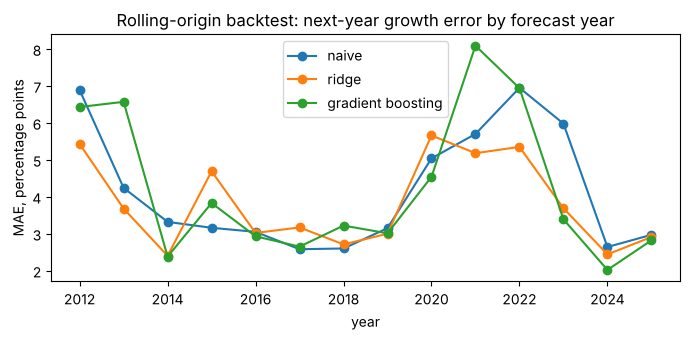

In [9]:
ax = bt[["naive", "ridge", "gradient boosting"]].plot(marker="o", figsize=(7, 3.5))
ax.set_ylabel("MAE, percentage points")
ax.set_title("Rolling-origin backtest: next-year growth error by forecast year")
plt.tight_layout()
plt.show()

**1.4 Drivers.** Permutation importance on the test set is model-agnostic and easy to explain to non-technical audiences.

In [10]:
from sklearn.inspection import permutation_importance

gb = models["gradient boosting"]
imp = permutation_importance(gb, test[X_COLS], test["target"], n_repeats=10, random_state=0, scoring="neg_mean_absolute_error")
pd.Series(imp.importances_mean * 100, index=X_COLS, name="MAE increase (pp) when shuffled").sort_values(ascending=False).round(3)

national_growth_1y    1.543
momentum_6m           0.902
growth_1y             0.398
growth_3y             0.198
log_value             0.193
volatility            0.060
Name: MAE increase (pp) when shuffled, dtype: float64

**Next steps:** add rent features from ZORI (available from 2015); quantile loss for prediction intervals; a hierarchical view that reconciles metro forecasts with state and national totals; and per-metro time-series baselines (ARIMA) to compare with the cross-sectional models.

---
## Part 2: SQL (DuckDB)

DuckDB runs SQL directly on pandas DataFrames, with no server. Its dialect is close to Snowflake's (`QUALIFY`, window functions).

In [11]:
import duckdb

con = duckdb.connect()
con.register("zhvi", zhvi)
con.register("zori", zori)
sql = lambda q: con.sql(q).df()

sql("SELECT RegionType, COUNT(DISTINCT RegionID) AS n_regions, MIN(date) AS first, MAX(date) AS last FROM zhvi GROUP BY 1")

,RegionType,n_regions,first,last
0,msa,894,2000-01-31,2026-09-30
1,country,1,2000-01-31,2026-09-30


**2.1** The 10 most expensive metros in the latest month.

In [12]:
sql('''
WITH latest AS (SELECT MAX(date) AS d FROM zhvi)
SELECT RegionName, StateName, ROUND(zhvi) AS zhvi
FROM zhvi, latest
WHERE RegionType = 'msa' AND date = latest.d
ORDER BY zhvi DESC
LIMIT 10
''')

,RegionName,StateName,zhvi
0,"Vineyard Haven, MA",MA,1556422.0
1,"San Jose, CA",CA,1523615.0
2,"Jackson, WY",WY,1437098.0
3,"Edwards, CO",CO,1297196.0
4,"Heber, UT",UT,1143939.0
5,"Santa Cruz, CA",CA,1136154.0
6,"Steamboat Springs, CO",CO,1121758.0
7,"San Francisco, CA",CA,1120379.0
8,"Hailey, ID",ID,1060567.0
9,"Kapaa, HI",HI,1014199.0


**2.2** Year-over-year growth for every metro and month, with `LAG(zhvi, 12)`.

In [13]:
yoy_sql = '''
SELECT RegionID, RegionName, StateName, date, zhvi,
       zhvi / LAG(zhvi, 12) OVER (PARTITION BY RegionID ORDER BY date) - 1 AS yoy
FROM zhvi
WHERE RegionType = 'msa'
'''
con.sql(f"CREATE OR REPLACE VIEW zhvi_yoy AS {yoy_sql}")

metro = "Austin, TX" if not SYNTHETIC else "Metro 1,"
sql(f'''
SELECT RegionName, date, ROUND(zhvi) AS zhvi, ROUND(100 * yoy, 1) AS yoy_pct
FROM zhvi_yoy
WHERE RegionName LIKE '{metro}%'
ORDER BY date DESC
LIMIT 6
''')

,RegionName,date,zhvi,yoy_pct
0,"Austin, TX",2026-09-30,414273.0,-4.3
1,"Austin, TX",2026-08-31,413658.0,-4.7
2,"Austin, TX",2026-07-31,413726.0,-5.2
3,"Austin, TX",2026-06-30,414823.0,-5.7
4,"Austin, TX",2026-05-31,417154.0,-6.0
5,"Austin, TX",2026-04-30,420109.0,-6.0


**2.3** Price-to-rent ratio (`zhvi / (12 * zori)`) in the latest month: which large metros are cheapest to buy relative to renting?

In [14]:
sql('''
WITH latest AS (SELECT MAX(date) AS d FROM zori)
SELECT v.RegionName, v.SizeRank,
       ROUND(v.zhvi) AS zhvi, ROUND(r.zori) AS zori,
       ROUND(v.zhvi / (12 * r.zori), 1) AS price_to_rent
FROM zhvi v
JOIN zori r USING (RegionID, date)
JOIN latest ON v.date = latest.d
WHERE v.RegionType = 'msa' AND v.SizeRank <= 50
ORDER BY price_to_rent
LIMIT 10
''')

,RegionName,SizeRank,zhvi,zori,price_to_rent
0,"Pittsburgh, PA",27,228201.0,1467.0,13.0
1,"New Orleans, LA",47,257067.0,1577.0,13.6
2,"Chicago, IL",3,355650.0,2163.0,13.7
3,"Memphis, TN",44,242102.0,1393.0,14.5
4,"Cleveland, OH",35,250001.0,1440.0,14.5
5,"Detroit, MI",14,264316.0,1514.0,14.6
6,"Oklahoma City, OK",42,243069.0,1384.0,14.6
7,"Tampa, FL",18,356843.0,1991.0,14.9
8,"Miami, FL",8,476815.0,2654.0,15.0
9,"Houston, TX",5,302832.0,1638.0,15.4


**2.4** The fastest-growing metro in each state, with `ROW_NUMBER()` and `QUALIFY`.

In [15]:
sql('''
SELECT StateName, RegionName, ROUND(100 * yoy, 1) AS yoy_pct
FROM zhvi_yoy
WHERE date = (SELECT MAX(date) FROM zhvi_yoy) AND yoy IS NOT NULL
QUALIFY ROW_NUMBER() OVER (PARTITION BY StateName ORDER BY yoy DESC) = 1
ORDER BY yoy_pct DESC
''')

,StateName,RegionName,yoy_pct
0,IL,"Galesburg, IL",11.8
1,WI,"Shawano, WI",11.4
2,ID,"Hailey, ID",10.7
3,MO,"Poplar Bluff, MO",10.1
4,TX,"Abilene, TX",9.7
5,NJ,"Ocean City, NJ",9.6
6,MS,"McComb, MS",9.4
7,MI,"Escanaba, MI",9.1
8,OK,"Guymon, OK",8.6
9,KS,"Great Bend, KS",8.6


**2.5** Peak-to-now drawdown: each metro's all-time peak, when it peaked, and how far the latest value sits below it.

In [16]:
sql('''
WITH stats AS (
    SELECT RegionID, RegionName,
           MAX(zhvi)            AS peak,
           ARG_MAX(date, zhvi)  AS peak_date,
           ARG_MAX(zhvi, date)  AS latest
    FROM zhvi
    WHERE RegionType = 'msa'
    GROUP BY RegionID, RegionName
)
SELECT RegionName, ROUND(peak) AS peak, peak_date, ROUND(latest) AS latest,
       ROUND(100 * (latest / peak - 1), 1) AS pct_below_peak
FROM stats
ORDER BY pct_below_peak
LIMIT 10
''')

,RegionName,peak,peak_date,latest,pct_below_peak
0,"Greenville, MS",114521.0,2019-06-30,53678.0,-53.1
1,"Clarksdale, MS",104453.0,2021-11-30,59852.0,-42.7
2,"Pecos, TX",303061.0,2022-05-31,178453.0,-41.1
3,"Bennettsville, SC",192241.0,2022-08-31,122988.0,-36.0
4,"Raymondville, TX",263807.0,2022-01-31,173347.0,-34.3
5,"Cleveland, MS",169891.0,2020-05-31,112026.0,-34.1
6,"Indianola, MS",137274.0,2021-12-31,93014.0,-32.2
7,"Alice, TX",181626.0,2009-10-31,125018.0,-31.2
8,"Helena, AR",66374.0,2020-11-30,46294.0,-30.3
9,"Zapata, TX",173203.0,2022-08-31,121682.0,-29.7


---
## Part 3: PySpark

The same metrics with the Spark API. Locally Spark runs on the laptop's cores; on a cluster the same code scales to much larger data.

In [17]:
from pyspark.sql import SparkSession, functions as F, Window

spark = (SparkSession.builder.master("local[*]").appName("housing-market-forecast")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

sdf_zhvi = spark.createDataFrame(zhvi)
sdf_zori = spark.createDataFrame(zori)
# For big files you would skip pandas entirely: spark.read.csv(path, header=True, inferSchema=True)
sdf_zhvi.printSchema()

Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=34781 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=
Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=34781 -Dhttp.nonProxyHosts=localhost|127.0.0.1

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/13 19:33:56 WARN Utils: Your hostname, vm, resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/11/13 19:33:56 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/13 19:33:57 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


root
 |-- RegionID: long (nullable = true)
 |-- SizeRank: long (nullable = true)
 |-- RegionName: string (nullable = true)
 |-- RegionType: string (nullable = true)
 |-- StateName: string (nullable = true)
 |-- date: timestamp (nullable = true)
 |-- zhvi: double (nullable = true)



**3.1** YoY growth with a window spec.

In [18]:
w = Window.partitionBy("RegionID").orderBy("date")
sdf_yoy = (sdf_zhvi.filter(F.col("RegionType") == "msa")
                   .withColumn("yoy", F.col("zhvi") / F.lag("zhvi", 12).over(w) - 1))

sdf_yoy.filter(F.col("RegionName").startswith(metro)).orderBy(F.desc("date")) \
       .select("RegionName", "date", F.round("zhvi").alias("zhvi"), F.round(100 * F.col("yoy"), 1).alias("yoy_pct")) \
       .show(6)

+----------+-------------------+--------+-------+
|RegionName|               date|    zhvi|yoy_pct|
+----------+-------------------+--------+-------+
|Austin, TX|2026-09-30 00:00:00|414273.0|   -4.3|
|Austin, TX|2026-08-31 00:00:00|413658.0|   -4.7|
|Austin, TX|2026-07-31 00:00:00|413726.0|   -5.2|
|Austin, TX|2026-06-30 00:00:00|414823.0|   -5.7|
|Austin, TX|2026-05-31 00:00:00|417154.0|   -6.0|
|Austin, TX|2026-04-30 00:00:00|420109.0|   -6.0|
+----------+-------------------+--------+-------+
only showing top 6 rows


**3.2** Latest price-to-rent ratio for large metros.

In [19]:
latest = sdf_zori.agg(F.max("date")).first()[0]
(sdf_zhvi.join(sdf_zori.select("RegionID", "date", "zori"), ["RegionID", "date"])
         .filter((F.col("date") == latest) & (F.col("RegionType") == "msa") & (F.col("SizeRank") <= 50))
         .withColumn("price_to_rent", F.round(F.col("zhvi") / (12 * F.col("zori")), 1))
         .select("RegionName", "SizeRank", "price_to_rent")
         .orderBy("price_to_rent")
         .show(10, truncate=False))

+-----------------+--------+-------------+
|RegionName       |SizeRank|price_to_rent|
+-----------------+--------+-------------+
|Pittsburgh, PA   |27      |13.0         |
|New Orleans, LA  |47      |13.6         |
|Chicago, IL      |3       |13.7         |
|Cleveland, OH    |35      |14.5         |
|Memphis, TN      |44      |14.5         |
|Detroit, MI      |14      |14.6         |
|Oklahoma City, OK|42      |14.6         |
|Tampa, FL        |18      |14.9         |
|Miami, FL        |8       |15.0         |
|Houston, TX      |5       |15.4         |
+-----------------+--------+-------------+
only showing top 10 rows


**3.3** Average YoY growth across metros, per state and year since 2018.

In [20]:
(sdf_yoy.filter(F.year("date") >= 2018)
        .withColumn("year", F.year("date"))
        .groupBy("StateName").pivot("year").agg(F.round(100 * F.avg("yoy"), 1))
        .orderBy("StateName")
        .show(15))

+---------+----+----+----+----+----+----+----+----+----+
|StateName|2018|2019|2020|2021|2022|2023|2024|2025|2026|
+---------+----+----+----+----+----+----+----+----+----+
|       AK| 3.2| 4.7| 4.1| 5.4| 6.5| 0.4| 1.4| 2.7| 4.9|
|       AL| 3.6| 4.8| 7.5|12.3|11.5| 2.6| 2.5| 1.2| 1.1|
|       AR| 3.7| 3.5| 6.9|11.5| 8.3| 0.8| 2.3|-0.3| 0.9|
|       AZ| 6.3| 8.0| 9.3|20.9|17.8|-0.3| 3.0| 0.4| 0.3|
|       CA| 8.4| 4.1| 4.9|15.6|12.4|-1.9| 2.9|-0.1|-0.2|
|       CO| 7.7| 6.3| 6.5|17.6|17.6| 0.6| 2.6| 1.0| 0.4|
|       CT| 2.3| 1.0| 4.5|16.1|11.4| 7.3| 9.4| 4.4| 4.9|
|       DE| 3.3| 4.5| 6.0|16.9|14.2| 4.2| 3.6| 1.6| 0.9|
|       FL| 8.0| 5.9| 6.9|17.8|24.9| 4.1| 1.6|-3.4|-2.3|
|       GA| 7.0| 7.2| 7.6|16.0|16.9| 4.5| 5.4| 0.7| 1.6|
|       HI| 5.1| 3.1| 4.5|13.3|19.8| 2.5| 2.9|-1.6|-0.9|
|       IA| 4.0| 4.4| 4.6| 8.8|10.7| 3.3| 3.4| 2.9| 3.7|
|       ID| 9.3| 9.9|12.7|29.0|18.4|-2.8| 2.1| 2.6| 3.2|
|       IL| 2.3| 3.1| 4.7| 7.3| 7.4| 3.4| 4.8| 4.3| 6.4|
|       IN| 6.5| 6.7| 7.5|14.4|

**3.4** Fastest-growing metro per state, in Spark SQL.

In [21]:
sdf_yoy.createOrReplaceTempView("zhvi_yoy")
spark.sql('''
SELECT StateName, RegionName, ROUND(100 * yoy, 1) AS yoy_pct
FROM (
    SELECT *, ROW_NUMBER() OVER (PARTITION BY StateName ORDER BY yoy DESC) AS rn
    FROM zhvi_yoy
    WHERE date = (SELECT MAX(date) FROM zhvi_yoy) AND yoy IS NOT NULL
)
WHERE rn = 1
ORDER BY yoy_pct DESC
''').show(10, truncate=False)

+---------+----------------+-------+
|StateName|RegionName      |yoy_pct|
+---------+----------------+-------+
|IL       |Galesburg, IL   |11.8   |
|WI       |Shawano, WI     |11.4   |
|ID       |Hailey, ID      |10.7   |
|MO       |Poplar Bluff, MO|10.1   |
|TX       |Abilene, TX     |9.7    |
|NJ       |Ocean City, NJ  |9.6    |
|MS       |McComb, MS      |9.4    |
|MI       |Escanaba, MI    |9.1    |
|OK       |Guymon, OK      |8.6    |
|KS       |Great Bend, KS  |8.6    |
+---------+----------------+-------+
only showing top 10 rows


---
## Part 4: Segmenting metros by market behavior

**Features per metro** (built in Spark, then passed to pandas for scikit-learn): `log_value` (price level), `growth_1y`, `growth_5y`, `volatility` (std. dev. of monthly changes over 5 years), `price_to_rent`, `rent_growth_1y`.

In [22]:
end = sdf_zhvi.agg(F.max("date")).first()[0]
w = Window.partitionBy("RegionID").orderBy("date")

monthly = (sdf_zhvi.filter(F.col("RegionType") == "msa")
                   .withColumn("mom", F.col("zhvi") / F.lag("zhvi", 1).over(w) - 1)
                   .withColumn("g1", F.col("zhvi") / F.lag("zhvi", 12).over(w) - 1)
                   .withColumn("g5", F.col("zhvi") / F.lag("zhvi", 60).over(w) - 1))

vol = (monthly.filter(F.col("date") > F.add_months(F.lit(end), -60))
              .groupBy("RegionID").agg(F.stddev("mom").alias("volatility")))

rent = (sdf_zori.withColumn("rent_growth_1y", F.col("zori") / F.lag("zori", 12).over(w) - 1)
                .filter(F.col("date") == end).select("RegionID", "zori", "rent_growth_1y"))

features = (monthly.filter(F.col("date") == end)
                   .select("RegionID", "RegionName", "StateName", "SizeRank", "zhvi",
                           F.log("zhvi").alias("log_value"), F.col("g1").alias("growth_1y"), F.col("g5").alias("growth_5y"))
                   .join(vol, "RegionID").join(rent, "RegionID")
                   .withColumn("price_to_rent", F.col("zhvi") / (12 * F.col("zori")))
                   .dropna()
                   .toPandas()
                   .set_index("RegionName"))

FEATS = ["log_value", "growth_1y", "growth_5y", "volatility", "price_to_rent", "rent_growth_1y"]
print(f"{len(features)} metros with complete features")
features[FEATS].describe().round(3)

593 metros with complete features


,log_value,growth_1y,growth_5y,volatility,price_to_rent,rent_growth_1y
count,593.000,593.000,593.000,593.000,593.000,593.000
mean,12.623,0.022,0.222,0.006,17.533,0.039
std,0.441,0.026,0.115,0.002,4.440,0.038
min,11.526,-0.133,-0.201,0.003,7.519,-0.044
25%,12.320,0.004,0.151,0.005,14.413,0.020
50%,12.583,0.023,0.237,0.006,16.912,0.033
75%,12.871,0.039,0.302,0.007,19.949,0.048
max,14.237,0.097,0.530,0.019,34.636,0.436


**4.1** Scale the features (k-means uses Euclidean distance), then choose *k* with the elbow and the silhouette score.

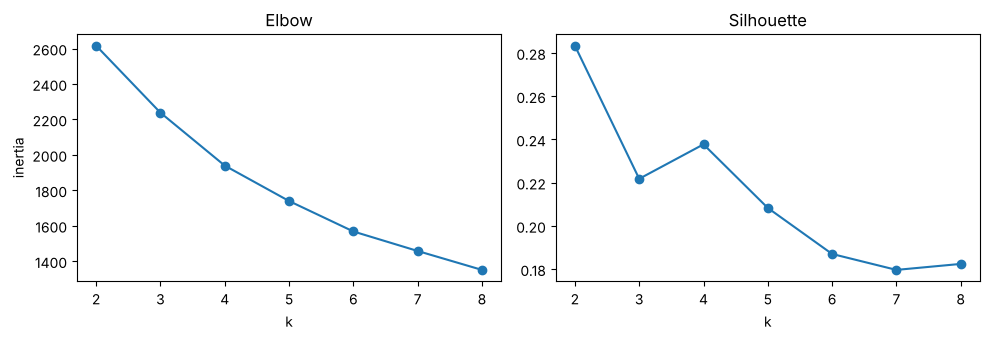

In [23]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X = StandardScaler().fit_transform(features[FEATS])
ks = range(2, 9)
fits = {k: KMeans(n_clusters=k, n_init=20, random_state=0).fit(X) for k in ks}

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(ks, [fits[k].inertia_ for k in ks], "o-"); ax[0].set(title="Elbow", xlabel="k", ylabel="inertia")
ax[1].plot(ks, [silhouette_score(X, fits[k].labels_) for k in ks], "o-"); ax[1].set(title="Silhouette", xlabel="k")
plt.tight_layout(); plt.show()

**4.2** Profile each segment: a segmentation is only useful if each segment can be named.

In [24]:
K = 4
km = fits[K]
features["segment"] = km.labels_

profile = features.groupby("segment").agg(
    n_metros=("zhvi", "size"),
    median_value=("zhvi", "median"),
    growth_1y=("growth_1y", "median"),
    growth_5y=("growth_5y", "median"),
    volatility=("volatility", "median"),
    price_to_rent=("price_to_rent", "median"),
    rent_growth_1y=("rent_growth_1y", "median"),
    example_metros=("SizeRank", lambda s: ", ".join(s.sort_values().index[:3])),
)
profile.style.format({"median_value": "${:,.0f}", "growth_1y": "{:.1%}", "growth_5y": "{:.1%}",
                      "volatility": "{:.4f}", "price_to_rent": "{:.1f}", "rent_growth_1y": "{:.1%}"})

,n_metros,median_value,growth_1y,growth_5y,volatility,price_to_rent,rent_growth_1y,example_metros
segment,,,,,,,,
0,168,"$242,586",0.6%,17.9%,0.0061,14.5,2.6%,"Houston, TX, Miami, FL, Atlanta, GA"
1,149,"$471,510",0.7%,14.6%,0.0068,21.6,2.6%,"Los Angeles, CA, Dallas, TX, Washington, DC"
2,6,"$188,655",5.8%,19.7%,0.0053,12.6,31.1%,"Lake Charles, LA, Abilene, TX, Indiana, PA"
3,270,"$268,199",3.8%,29.5%,0.0046,16.7,4.1%,"New York, NY, Chicago, IL, Philadelphia, PA"


**4.3** The segments in two dimensions with PCA.

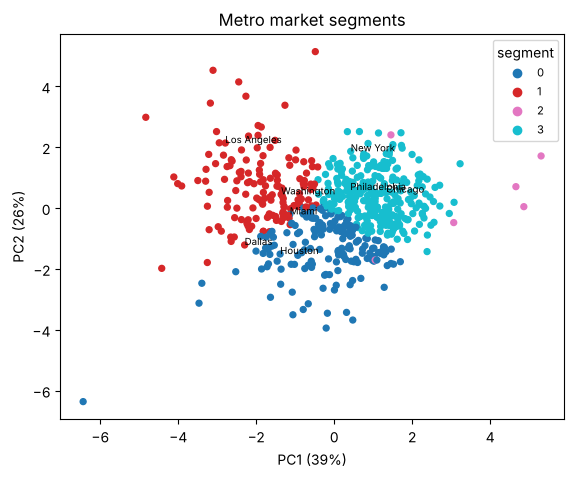

,PC1,PC2
log_value,-0.45,0.52
growth_1y,0.47,0.41
growth_5y,0.38,0.40
volatility,-0.45,-0.19
price_to_rent,-0.39,0.59
rent_growth_1y,0.28,0.11


In [25]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2).fit(X)
Z = pca.transform(X)
fig, ax = plt.subplots(figsize=(6.5, 5))
sc = ax.scatter(Z[:, 0], Z[:, 1], c=features["segment"], cmap="tab10", s=18)
for name in features.sort_values("SizeRank").index[:8]:
    i = features.index.get_loc(name)
    ax.annotate(name.split(",")[0], Z[i], fontsize=7)
ax.set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%})", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})",
       title="Metro market segments")
ax.legend(*sc.legend_elements(), title="segment", fontsize=8)
plt.show()

pd.DataFrame(pca.components_.T, index=FEATS, columns=["PC1", "PC2"]).round(2)

In [26]:
spark.stop()